# Revisión de vigas — ACI 318-25
Flexión + corte de viga sísmica (SMF, §18.6). Cláusulas: §9 (vigas), §22.2 (flexión), §22.5 (corte), §18.6.4 (confinamiento), §18.6.5 (Mpr, Ve).

**Unidades:** resultados en m / tonf; materiales en MPa.
**Mpr de viga = momento probable a axial cero (P=0).**

In [1]:
import sys, pathlib
# Make the notebook self-contained: add the repo root (the folder that
# contains design/common) to sys.path regardless of the run cwd.
ROOT = pathlib.Path.cwd()
for _ in range(5):
    if (ROOT / 'design' / 'common').is_dir():
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from design import Concrete, Steel, Bar, Beam, Column, Wall
from design import RectangularSection, WallSection
from design.beams.beam import BeamDemands
from design.columns.column import ColumnDemands
from design.walls.wall import WallDemands
from design.sections.reinforcement import RebarLayout, perimeter_bars, two_layer_bars
from design.common.units import units_from
from design.common.probable import mpr_at_axial, probable_interaction_diagram
from design.analysis.section_analysis import pm_curve

# Presentation: results in tonf / m ; materials in MPa (N/mm^2)
U = units_from('Tonf_m_C')      # forces -> tonf, moments -> tonf*m, lengths -> m
MAT = units_from('N_mm_C')      # stresses -> MPa
print('Results in:', U.name, '| materials in:', MAT.name)
print('1 tonf =', round(1/U.force_factor, 5), 'kN')


Results in: Tonf_m_C | materials in: N_mm_C
1 tonf = 9.80665 kN


In [2]:
def plot_pm(diagram, *, title, demand=None, mark_p0=True, nominal=None):
    """Plot a phi-reduced P-M interaction diagram (tonf, tonf*m), marking
    the Mpr at zero axial and an optional demand point."""
    Mn = np.array(diagram.phi_Mn) * U.moment_factor
    Pn = np.array(diagram.phi_Pn) * U.force_factor
    fig, ax = plt.subplots(figsize=(5.2, 5.6))
    ax.plot(Mn, Pn, '-', lw=2, color='#1f77b4', label='phi P-M (design)')
    if nominal is not None:
        Mnn = np.array([p.Mn for p in nominal.points]) * U.moment_factor
        Pnn = np.array([p.Pn for p in nominal.points]) * U.force_factor
        order = np.argsort(Pnn)
        ax.plot(Mnn[order], Pnn[order], '--', lw=1.2, color='#888',
                label='nominal P-M')
    if mark_p0:
        # moment at P = 0 (Mpr-style) read off the nominal curve
        if nominal is not None:
            order = np.argsort([p.Pn for p in nominal.points])
            Pn_s = np.array([nominal.points[i].Pn for i in order])
            Mn_s = np.array([nominal.points[i].Mn for i in order])
            m0 = float(np.interp(0.0, Pn_s, Mn_s)) * U.moment_factor
            ax.plot(m0, 0.0, 'o', color='crimson', ms=8,
                    label=f'M at P=0 = {m0:.1f} tonf*m')
    if demand is not None:
        md_, pd_ = demand
        ax.plot(md_, pd_, 's', color='green', ms=9, label='demand')
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xlabel('phi*Mn  [tonf*m]'); ax.set_ylabel('phi*Pn  [tonf]')
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


## Ejercicio 1 — Evaluar y verificar un armado mínimo
Se parte de una viga 300×600 con la **armadura mínima** de flexión (§9.6.1.2: $A_{s,min}=\max(0.25\sqrt{f'_c}/f_y,\,1.4/f_y)\,b_w d$).

In [3]:
c = Concrete(fc=28); s = Steel(fy=420, grade=60)
bw, h, cover = 300.0, 600.0, 40.0
d = h - cover - 10 - 16/2
As_min = max(0.25*np.sqrt(c.fc)/s.fy, 1.4/s.fy) * bw * d
print(f'd = {d:.0f} mm   As_min = {As_min:.0f} mm^2  '
      f'(=> 3 phi16 = {3*201:.0f} mm^2)')
beam = Beam.rectangular(bw=bw, h=h, cover=cover, concrete=c, steel=s,
    n_top=2, db_top=16, n_bot=3, db_bot=16,
    db_stirrup=10, n_legs=2, s_stirrup=150, ln=5000,
    seismic=True, Vg=60.0, label='V1-min')
beam.run()
beam.summary()

d = 542 mm   As_min = 542 mm^2  (=> 3 phi16 = 603 mm^2)
=== V1-min ===  (units: N_mm_C)
Section   : 300x600 mm
Materials : fc = 28 MPa, fy = 420 MPa
Rebar     : 5 bars, As_tot = 1005 mm^2
            rho  = 0.0037  (bottom)
            rho' = 0.0025  (top)
            range [rho_min = 0.0033 .. rho_max = 0.0142]
            rho_b = 0.0283  (rho_max = 0.5*rho_b)
phi*Mn+   : 119533323.9 N.mm
phi*Mn-   : 80587764.3 N.mm
phi*Vn    : 288488.8 N
Mpr+      : 164614002.6 N.mm
Mpr-      : 111303227.0 N.mm
TC        : True
Stirrups  : phi10 x 2 legs @ 150 mm
Steel quantities (kg/m^3 of concrete):
  rho_long  = 43.84
  rho_trans = 32.88
  rho_total = 76.72


### 1.2 Capacidades y Mpr a P=0
`capacity()` entrega $\phi M_n$, $\phi V_n$ y el momento probable $M_{pr}$ (con $f_{y,pr}=1.25 f_y$, $\phi=1$). Para vigas el $M_{pr}$ es el momento del diagrama de interacción **cuando la axial es cero**.

In [4]:
cap = beam.capacity()
print('fc  =', MAT.fmt_stress(c.fc), '| fy =', MAT.fmt_stress(s.fy))
print('phi_Mn_pos =', U.fmt_moment(cap.phi_Mn_pos),
      '| phi_Mn_neg =', U.fmt_moment(cap.phi_Mn_neg))
print('Mpr_pos    =', U.fmt_moment(cap.Mpr_pos),
      '| Mpr_neg =', U.fmt_moment(cap.Mpr_neg))
print('phi_Vn     =', U.fmt_force(cap.phi_Vn))
# cross-check: Mpr_pos equals the probable moment at P=0 on the section
print('Mpr@P=0 (section diagram) =', U.fmt_moment(mpr_at_axial(beam.section, Nu=0.0)))

fc  = 28.00 N/mm^2 | fy = 420.00 N/mm^2
phi_Mn_pos = 12.2 Tonf.m | phi_Mn_neg = 8.2 Tonf.m
Mpr_pos    = 16.8 Tonf.m | Mpr_neg = 11.3 Tonf.m
phi_Vn     = 29.4 Tonf
Mpr@P=0 (section diagram) = 16.8 Tonf.m


### 1.3 Diagrama de interacción P-M con el Mpr a P=0
El diagrama probable de la sección; el punto rojo es el $M_{pr}$ a $P=0$.

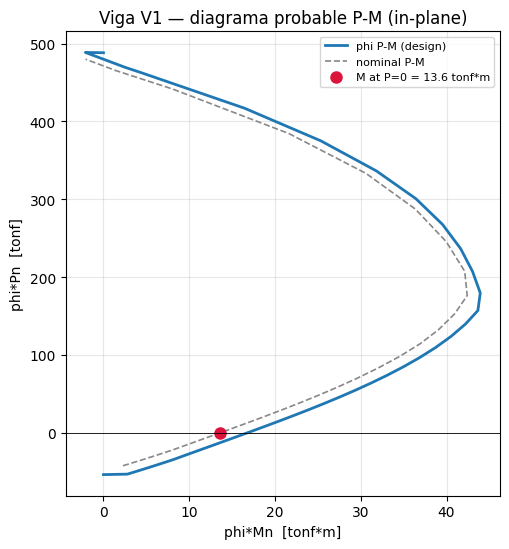

In [5]:
diag = probable_interaction_diagram(beam.section, angle_deg=0.0)
nom = pm_curve(beam.section, n_points=60, angle_deg=0.0)
plot_pm(diag, title='Viga V1 — diagrama probable P-M (in-plane)', nominal=nom)

### 1.4 Demandas y verificación
Se aplican momentos y cortantes mayorados (en tonf·m / tonf). `print_checks` reporta razón demanda/capacidad por estación.

In [6]:
# demands in kN·m / kN internally; here given directly
dem = BeamDemands(
    Mu_pos_i=8.0,  Mu_neg_i=20.0, Vu_i=18.0,
    Mu_pos_mid=22.0, Mu_neg_mid=5.0, Vu_mid=8.0,
    Mu_pos_j=8.0,  Mu_neg_j=20.0, Vu_j=18.0)
beam.print_checks(dem)

=== V1-min -- ACI 318-25 Checks ===  (units: N_mm_C)
Sec.9.6.1.2 / 22.2  Cuantia (range 0.5*rho_b):
  rho  (bot) = 0.0037    [0.0033 .. 0.0142]   OK
  rho' (top) = 0.0025    [0.0033 .. 0.0142]   FAIL
  rho_balanced = 0.0283    (ACI Sec.18.6.3.1 SMF cap = 0.0250)
Sec.21.2.2          Tension-controlled                          : OK
Sec.18.6.3.2        >=2 bars continuous (top, bot)            : requires layout check at apply()
Sec.18.6.3.3        phi_Mn+ >= 0.5 phi_Mn-                    : 1.48   OK
Sec.18.6.3.4        phi_Mn anywhere >= 0.25 max               : 0.67   OK
Demand ratios (per station):
  M (i)  +/-: 0.07 / 0.25
  M (mid)+/-: 0.18 / 0.06
  M (j)  +/-: 0.07 / 0.25
  V (i/mid/j): 0.06 / 0.03 / 0.06
  Overall passed = True
---
Steel quantities (kg/m^3 of concrete):
  rho_long  = 43.84
  rho_trans = 32.88
  rho_total = 76.72


### 1.5 Ajuste del diseño para cumplir las demandas
`design()` parte del mínimo y propone el armado que cumple.

In [7]:
results = beam.design(dem)
beam.print_design(results, demands=dem)

=== V1-min Design Results ===  (units: N_mm_C)

--- PROVIDED ---
  Top         : 2phi16    (As = 402 mm^2)
  Bottom      : 3phi16    (As = 603 mm^2)
  Stirrups    : phi10 x 2 legs @ 150 mm
  phi*Mn (+/-): 119533323.9 N.mm / 80587764.3 N.mm
  phi*Vn      : 288488.8 N
  Mpr (+/-)   : 164614002.6 N.mm / 111303227.0 N.mm   -> Ve_capacity = 115183.4 N
  rho / rho'  : 0.0037 / 0.0025    range [0.0033 .. 0.0142]    FAIL
  Demand check: ratio M = 0.25   ratio V (i/m/j) = 0.06 / 0.03 / 0.06   passed = True

--- MINIMUM ---
  Top         : 5phi12    (As = 565 mm^2)
  Bottom      : 5phi12    (As = 565 mm^2)
  Stirrups    : phi10 x 2 legs @ 72 mm   (middle s = 271 mm, lo = 1200 mm)
  Mpr (+/-)   : 164614002.6 N.mm / 111303227.0 N.mm   -> Ve_capacity = 115183.4 N
  phi*Vn      : 482175.9 N   Ve/phiVn = 0.24
  steel (kg/m^3): rho_long = 49.3    rho_trans = 68.5    rho_total = 117.8

--- DEMAND ---
  Top         : 5phi12    (As = 565 mm^2)
  Bottom      : 5phi12    (As = 565 mm^2)
  Stirrups    : phi

## Ejercicio 2 — Diseño desde la sección y las demandas
Geometría fija (300×600) y demandas dadas → armado automático.

In [8]:
dem2 = BeamDemands(
    Mu_pos_i=12.0, Mu_neg_i=30.0, Vu_i=25.0,
    Mu_pos_mid=35.0, Mu_neg_mid=8.0, Vu_mid=12.0,
    Mu_pos_j=12.0, Mu_neg_j=30.0, Vu_j=25.0)
res2 = beam.design(dem2)
env = res2.envelope
print('Top bars   :', env.n_top, 'phi', env.db_top)
print('Bot bars   :', env.n_bot, 'phi', env.db_bot)
print('Stirrups   : phi', env.db_stirrup, 'legs', env.n_legs,
      '@', U.fmt_length(env.spacing_confined), '(confined)')
print('Mpr_pos    =', U.fmt_moment(env.Mpr_pos), '| Mpr_neg =', U.fmt_moment(env.Mpr_neg))

Top bars   : 5 phi 12
Bot bars   : 5 phi 12
Stirrups   : phi 10 legs 2 @ 0.072 m (confined)
Mpr_pos    = 16.8 Tonf.m | Mpr_neg = 11.3 Tonf.m


## Resumen
- $M_{pr}$ de viga verificado = momento a $P=0$ (§18.6.5.1).
- Confinamiento $s\le\min(d/4,6d_b,150)$ con $d_b$ real (§18.6.4.4).
- $V_c=0$ en la zona crítica cuando el sismo gobierna (§18.6.5.2).
- Cuantía mínima $A_{s,min}$ (§9.6.1.2) y máxima 0.025 (§18.6.3.1).